# Exploratory Data Analysis (EDA)

**CS316 Electricity Theft Detection, Member 2 (EDA and feature engineering)**

This notebook explores the cleaned **training** data of both datasets:

- **SGCC** (China): daily electricity use, one row per customer.
- **OEDI** (USA): hourly electricity and gas use of 16 building types, one row per hour.
  The theft in this dataset was simulated by the dataset authors.

Rules:

- **Training files only.** The test files are kept for the final evaluation (Member 3).
  Looking at them now would let test data influence our decisions (data leakage).
- **SGCC and OEDI are kept separate.**
- The data was cleaned by Member 1's code (`python -m src.prepare_data`).
  The checks behind the cleaning are in `01_data_quality.ipynb`.

Sections:

0. Setup
1. Load and check the training files
2. Class balance
3. Missing data (SGCC)
4. Usage over time
5. Normal vs theft
6. Does gas use change during theft? (OEDI)
7. Summary of findings

## 0. Setup

Upload **only the two training files** to Google Drive:

```
MyDrive/cs316-data/processed/sgcc/train.csv
MyDrive/cs316-data/processed/oedi/train.csv
```

The charts are saved to `MyDrive/cs316-data/figures/` for the report and slides.

In [33]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# In Colab: connect Google Drive. On a laptop: use the project folders.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/cs316-data/processed"
    FIG_DIR = "/content/drive/MyDrive/cs316-data/figures"
except ImportError:
    DATA_DIR = "../data/processed"
    FIG_DIR = "../outputs/figures"

os.makedirs(FIG_DIR, exist_ok=True)  # create the figures folder if needed

# The same colours in every chart: blue = normal, orange = theft.
BLUE = "#2a78d6"
ORANGE = "#eb6834"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Load and check the training files

First we make sure we loaded the right files. A wrong file (for example `test.csv`)
would make every chart below wrong.

In [34]:
# SGCC: read the readings as float32, which uses half the memory of the default.
sgcc_columns = pd.read_csv(f"{DATA_DIR}/sgcc/train.csv", nrows=0).columns
dtypes = {c: np.float32 for c in sgcc_columns if c not in ("CONS_NO", "FLAG")}
sgcc = pd.read_csv(f"{DATA_DIR}/sgcc/train.csv", dtype=dtypes)

# OEDI
oedi = pd.read_csv(f"{DATA_DIR}/oedi/train.csv")

# The SGCC day columns: every column except the ID, the label and missing_share.
DAYS = [c for c in sgcc.columns if c not in ("CONS_NO", "FLAG", "missing_share")]

print("SGCC:", sgcc.shape, "(customers, columns)")
print("OEDI:", oedi.shape, "(hours, columns)")

SGCC: (33893, 1038) (customers, columns)
OEDI: (420480, 15) (hours, columns)


In [35]:
# The expected sizes come from Member 1's handoff.
# assert stops the notebook with a message if the condition is False.
assert len(sgcc) == 33893, "Wrong SGCC file - is it the training file?"
assert len(oedi) == 420480, "Wrong OEDI file - is it the training file?"

print("SGCC days:", len(DAYS), "from", DAYS[0], "to", DAYS[-1])
print("SGCC missing values:", sgcc.isna().sum().sum())
print("OEDI recordings:", oedi["recording_id"].nunique())
print("OEDI building types:", oedi["building_type"].nunique())
print("OEDI missing values:", oedi.isna().sum().sum())

SGCC days: 1035 from 2014-01-01 to 2016-10-31
SGCC missing values: 0
OEDI recordings: 48
OEDI building types: 16
OEDI missing values: 0


**Result:** both files are the right ones: 33,893 SGCC customers with 1,035 days each,
and 48 OEDI recordings (one year each) of 16 building types. There are no missing
values, because Member 1's cleaning filled the gaps.

## 2. Class balance

**Question:** how many examples are theft, and how many are normal?

In [36]:
# value_counts() counts each label. sort_index() puts 0 (normal) before 1 (theft).
sgcc_counts = sgcc["FLAG"].value_counts().sort_index()
oedi_counts = oedi["theft"].value_counts().sort_index()

print("SGCC customers:", sgcc_counts.tolist(), "-> theft share", round(sgcc_counts[1] / len(sgcc), 3))
print("OEDI hours:    ", oedi_counts.tolist(), "-> theft share", round(oedi_counts[1] / len(oedi), 3))

SGCC customers: [31003, 2890] -> theft share 0.085
OEDI hours:     [248955, 171525] -> theft share 0.408


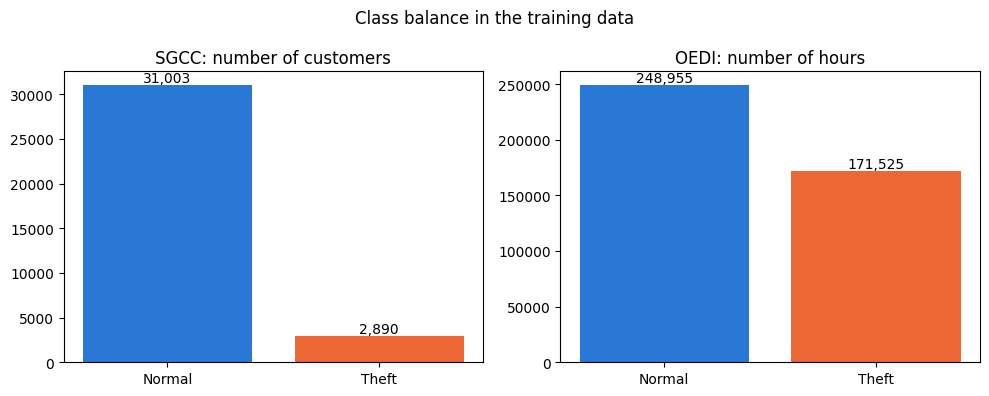

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

bars = axes[0].bar(["Normal", "Theft"], sgcc_counts, color=[BLUE, ORANGE])
axes[0].bar_label(bars, fmt="{:,.0f}")   # write the number on each bar
axes[0].set_title("SGCC: number of customers")

bars = axes[1].bar(["Normal", "Theft"], oedi_counts, color=[BLUE, ORANGE])
axes[1].bar_label(bars, fmt="{:,.0f}")
axes[1].set_title("OEDI: number of hours")

plt.suptitle("Class balance in the training data")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig01_class_balance.png", dpi=150)
plt.show()

In [38]:
# A "model" that always answers "normal" never finds any theft. How accurate is it?
print("SGCC: always 'normal' is right", round(sgcc_counts[0] / len(sgcc) * 100, 1), "% of the time")
print("OEDI: always 'normal' is right", round(oedi_counts[0] / len(oedi) * 100, 1), "% of the time")

SGCC: always 'normal' is right 91.5 % of the time
OEDI: always 'normal' is right 59.2 % of the time


**Insight:**

- **SGCC is very imbalanced:** only 8.5% of customers are theft (about 1 in 12).
- A model that always says "normal" is **91.5% accurate on SGCC but finds no theft at
  all**. So accuracy alone is misleading (the "99.55% accurate guard" example from the
  Classification lecture). We must also look at **precision and recall**, and the models
  need **class weights**.
- **OEDI is more balanced** (40.8% theft hours), because the theft was added on purpose.
- The two datasets count different things (customers vs hours), so their results should
  not be compared directly.

## 3. Missing data (SGCC)

**Question:** do theft customers have more missing readings than normal customers?

25.6% of the raw SGCC readings were missing. Member 1 filled them, but kept each
customer's share of missing days in the column `missing_share` (0 = none, 1 = all).
OEDI had no missing values.

In [39]:
# Split the customers into two groups (like the lecture's boxplot example).
normal = sgcc[sgcc["FLAG"] == 0]
theft = sgcc[sgcc["FLAG"] == 1]

# describe() gives count, mean, std, min, quartiles (25%, 50% = median, 75%) and max.
pd.DataFrame({
    "Normal": normal["missing_share"].describe(),
    "Theft": theft["missing_share"].describe(),
}).round(3)

,Normal,Theft
count,31003.000,2890.000
mean,0.252,0.313
std,0.287,0.292
min,0.001,0.001
25%,0.013,0.022
50%,0.095,0.212
75%,0.579,0.706
max,0.996,0.997


In [40]:
# Put each customer in a band by how much data was missing.
bands = pd.cut(sgcc["missing_share"],
               bins=[0, 0.10, 0.25, 0.50, 0.75, 1.0],
               labels=["0-10%", "10-25%", "25-50%", "50-75%", "75-100%"],
               include_lowest=True)

# Cross-table: in each band, the share of normal (0) and theft (1) customers.
band_table = pd.crosstab(bands, sgcc["FLAG"], normalize="index")
band_table["customers"] = bands.value_counts()
band_table.round(3)

FLAG,0,1,customers
missing_share,,,
0-10%,0.934,0.066,16757
10-25%,0.902,0.098,4795
25-50%,0.894,0.106,3381
50-75%,0.896,0.104,8649
75-100%,0.807,0.193,311


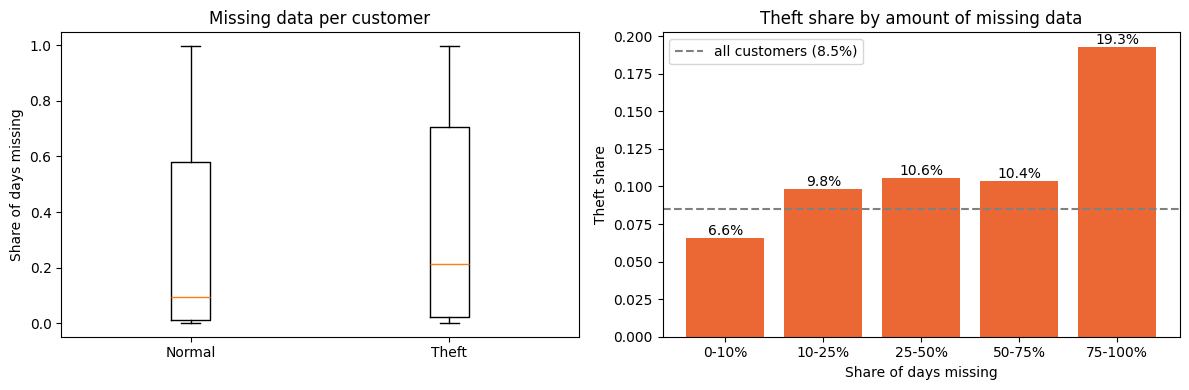

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: box plot. The line inside each box is the median customer.
axes[0].boxplot([normal["missing_share"], theft["missing_share"]])
axes[0].set_xticks([1, 2], ["Normal", "Theft"])
axes[0].set_ylabel("Share of days missing")
axes[0].set_title("Missing data per customer")

# Right: theft share in each band, compared with the overall theft share.
bars = axes[1].bar(band_table.index, band_table[1], color=ORANGE)
axes[1].bar_label(bars, fmt="{:.1%}")
axes[1].axhline(sgcc["FLAG"].mean(), color="gray", linestyle="--", label="all customers (8.5%)")
axes[1].set_xlabel("Share of days missing")
axes[1].set_ylabel("Theft share")
axes[1].set_title("Theft share by amount of missing data")
axes[1].legend()

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig02_missing_share.png", dpi=150)
plt.show()

**Insight:**

- **Theft customers had more missing readings:** the median theft customer was missing
  21% of their days, more than double the 9.5% of the median normal customer.
- **The more data is missing, the higher the theft share:** from 6.6% (0-10% missing)
  up to 19.3% (more than 75% missing; only 311 customers, so less certain).
- So `missing_share` is a **useful clue** for the models (PR 4).
- **But it is not proof:** the boxes overlap a lot, and a broken meter also causes gaps.
  A flag is never an accusation.

## 4. Usage over time

**Questions:** how does SGCC usage change over the months? How does OEDI usage change
over the 24 hours of a day? Usage goes up and down for normal reasons too, and the
models must not confuse that with theft.

### 4a. SGCC: usage by month

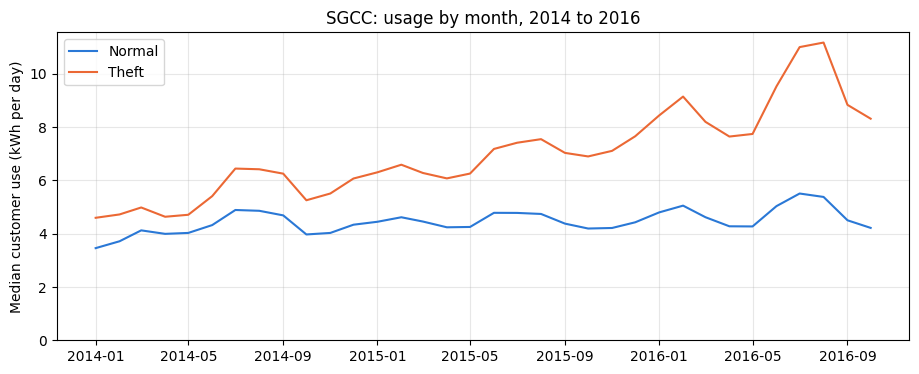

In [42]:
# For each day, take the median customer of each group
# (the median is not pulled up by a few very large customers).
normal_daily = normal[DAYS].median()
theft_daily = theft[DAYS].median()

# Turn the column names into real dates, then take the average of each month.
normal_daily.index = pd.to_datetime(normal_daily.index)
theft_daily.index = pd.to_datetime(theft_daily.index)
normal_monthly = normal_daily.resample("MS").mean()
theft_monthly = theft_daily.resample("MS").mean()

plt.figure(figsize=(11, 4))
plt.plot(normal_monthly, color=BLUE, label="Normal")
plt.plot(theft_monthly, color=ORANGE, label="Theft")
plt.ylabel("Median customer use (kWh per day)")
plt.title("SGCC: usage by month, 2014 to 2016")
plt.ylim(bottom=0)
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(f"{FIG_DIR}/fig03_sgcc_monthly.png", dpi=150)
plt.show()

**Insight:**

- **Usage follows the seasons:** both groups peak every summer (July-August, probably
  air conditioning) and rise a little in winter. Every autumn, usage drops for everyone.
- **Surprise: theft customers record MORE electricity, not less** (in July 2016, about
  11 kWh/day vs 5.5 for normal customers). So "low usage = theft" is wrong here.
- **What this means for the features:** a drop alone is normal (seasons). We should
  compare each customer with **their own** usual use, not with a fixed limit.

### 4b. OEDI: usage by hour of the day

The column `hour` counts the hours of a whole year (0 to 8,759). The hour of the day
is `hour % 24`: the remainder after dividing by 24 (0 = midnight, 13 = 1 pm).
We use **normal hours only**, to see each building's real daily rhythm.

In [43]:
oedi["hour_of_day"] = oedi["hour"] % 24
normal_hours = oedi[oedi["theft"] == 0]

# Average electricity for each building type and each hour of the day.
# unstack() turns the 24 hours into columns: one row per building type.
profile = normal_hours.groupby(["building_type", "hour_of_day"])["elec_facility_kw"].mean().unstack()

pd.DataFrame({
    "busiest hour": profile.idxmax(axis=1),
    "quietest hour": profile.idxmin(axis=1),
    "busiest / quietest": (profile.max(axis=1) / profile.min(axis=1)).round(1),
})

,busiest hour,quietest hour,busiest / quietest
building_type,,,
FullServiceRestaurant,17,1,3.5
Hospital,10,2,1.5
LargeHotel,19,2,2.4
LargeOffice,15,2,3.7
MediumOffice,8,23,3.2
MidriseApartment,18,2,2.5
OutPatient,13,2,2.8
PrimarySchool,14,21,2.9
QuickServiceRestaurant,18,1,3.1


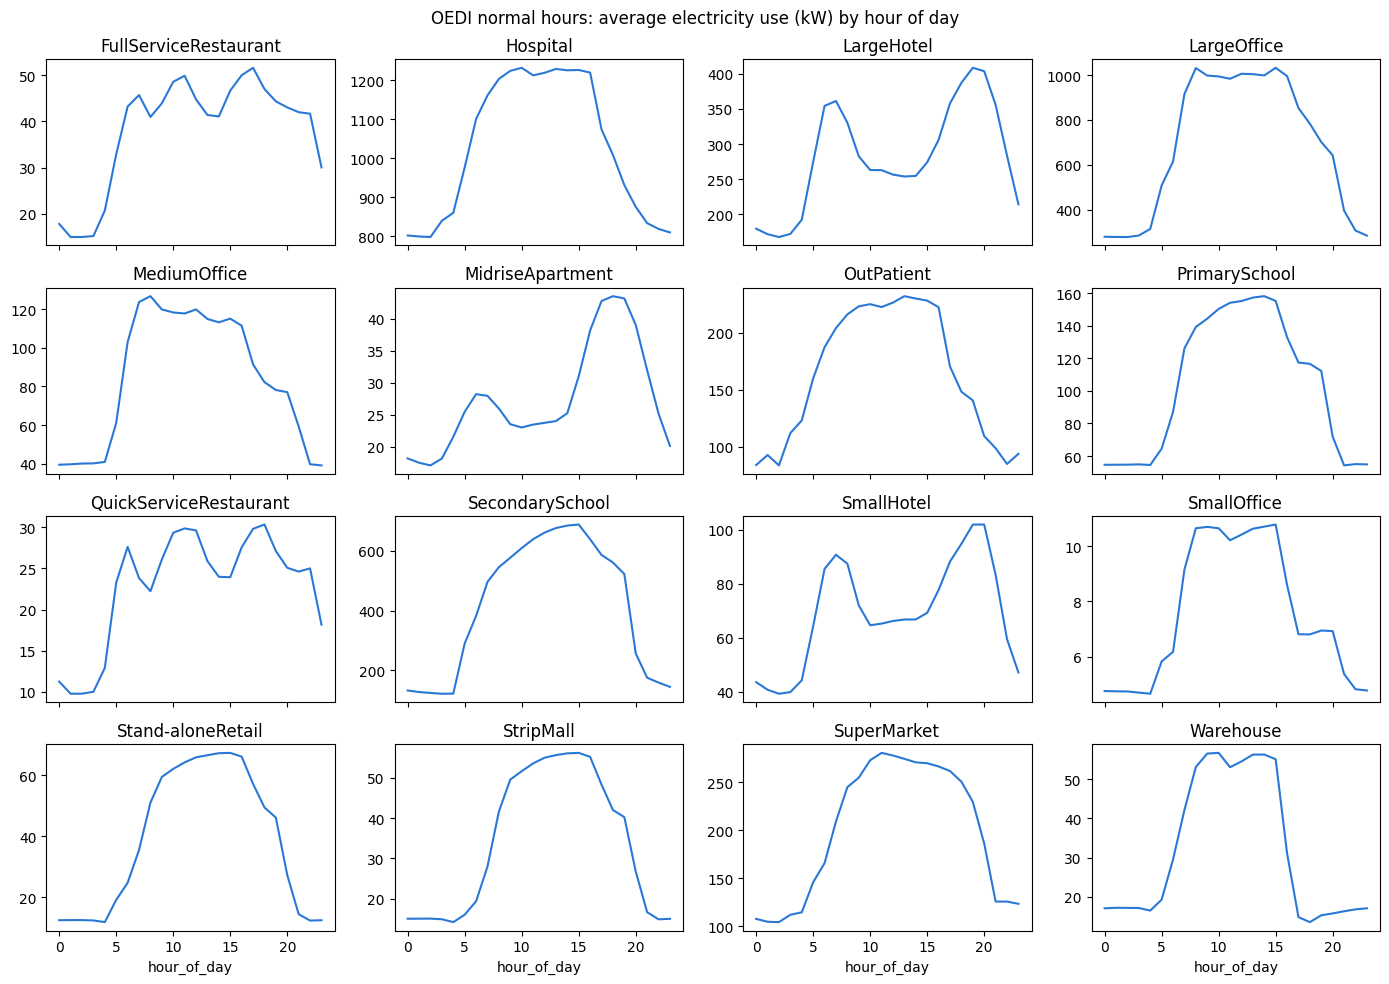

In [44]:
# One small chart per building type. Each has its own scale,
# because a hospital uses about 100 times more than a small office.
profile.T.plot(subplots=True, layout=(4, 4), figsize=(14, 10), sharex=True,
               legend=False, title=list(profile.index), color=BLUE)
plt.suptitle("OEDI normal hours: average electricity use (kW) by hour of day")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig04_oedi_daily.png", dpi=150)
plt.show()

**Insight:**

- **Each building type has its own daily rhythm.** Offices, schools and shops are busy
  during the day and quiet at night. Hotels and apartments have a morning and an evening
  peak. The hospital is busy day and night (its busiest hour is only 1.5 times its
  quietest).
- **Sizes are very different** (hospital about 1,230 kW, small office about 11 kW),
  so a fixed limit like "below 50 kW is suspicious" makes no sense.
- **For the features:** use the **hour of day**, and compare each hour with the same
  building's usual level, calculated inside each `recording_id`.

## 5. Normal vs theft

**Questions:** do theft customers use electricity differently? And in OEDI, how does
each of the six theft types change the usage?

### 5a. SGCC: three simple numbers per customer

For every customer we calculate three numbers from their 1,035 days. These are the
kind of summary numbers (features) that PR 4 will build:

- **average use** (mean kWh per day),
- **variability** (standard deviation: how much the use jumps around),
- **share of zero days** (days with a reading of 0).

In [45]:
# axis=1 means "along the row", so each customer gets their own numbers.
customer_stats = pd.DataFrame({
    "average use": sgcc[DAYS].mean(axis=1),
    "variability": sgcc[DAYS].std(axis=1),
    "share of zero days": (sgcc[DAYS] == 0).mean(axis=1),
    "FLAG": sgcc["FLAG"],
})

# The median of each number, for normal (0) and theft (1) customers.
customer_stats.groupby("FLAG").median().round(3)

,average use,variability,share of zero days
FLAG,,,
0,5.183,2.553,0.007
1,8.124,5.063,0.003


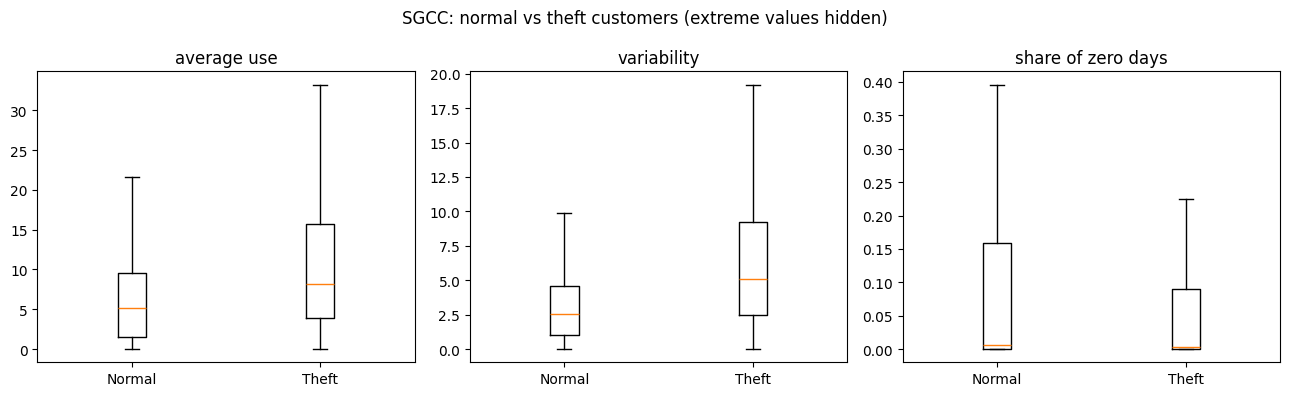

Customers with more than half zero days:
  normal: 16.8 %
  theft:  8.5 %


In [46]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, column in zip(axes, ["average use", "variability", "share of zero days"]):
    ax.boxplot([customer_stats.loc[customer_stats["FLAG"] == 0, column],
                customer_stats.loc[customer_stats["FLAG"] == 1, column]],
               showfliers=False)   # hide extreme points so the boxes are readable
    ax.set_xticks([1, 2], ["Normal", "Theft"])
    ax.set_title(column)

plt.suptitle("SGCC: normal vs theft customers (extreme values hidden)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig05_sgcc_normal_vs_theft.png", dpi=150)
plt.show()

# How common are customers with mostly zero days, in each group?
mostly_zero = customer_stats["share of zero days"] > 0.5
print("Customers with more than half zero days:")
print("  normal:", round(mostly_zero[customer_stats["FLAG"] == 0].mean() * 100, 1), "%")
print("  theft: ", round(mostly_zero[customer_stats["FLAG"] == 1].mean() * 100, 1), "%")

**Insight:**

- **Theft customers use more, and their use jumps around more:** median average use
  8.1 vs 5.2 kWh/day, median variability 5.1 vs 2.6.
- **Zero days do NOT point to theft here:** customers with more than half zero days are
  *more* common among normal customers (16.8%) than among theft customers (8.5%).
  Many zero days probably mean an empty home, not theft.
- So in SGCC, theft shows in **how irregular** the use is, more than in low use or zeros.
  Variability and sudden drops are worth building as features in PR 4.

### 5b. OEDI: what each theft type does

The six theft types were made by the dataset authors (Zidi et al., 2022):

| Type | What was done to the readings |
|---|---|
| Theft1 | daytime use multiplied by a random value between 0.1 and 0.8 |
| Theft2 | use set to zero for a random period |
| Theft3 | each hour multiplied by its own random number |
| Theft4 | replaced by a random fraction of the average use |
| Theft5 | replaced by the average use |
| Theft6 | readings in reverse order |

Buildings have very different sizes, so we compare each hour with **its own
building's average**: a value of 1.0 means "a normal amount for this building".

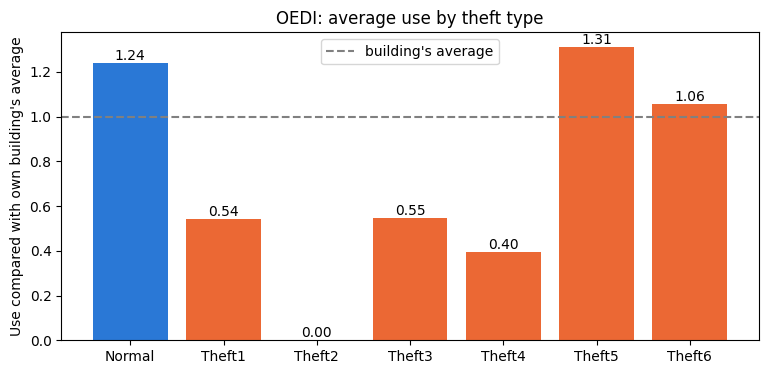

In [47]:
# Divide each hour by the average of its own recording.
# groupby("recording_id") keeps every building separate; transform("mean")
# gives each row the average of its own recording.
building_average = oedi.groupby("recording_id")["elec_facility_kw"].transform("mean")
oedi["elec_vs_average"] = oedi["elec_facility_kw"] / building_average

by_type = oedi.groupby("theft_type")["elec_vs_average"].mean()

plt.figure(figsize=(9, 4))
bars = plt.bar(by_type.index, by_type, color=[BLUE] + [ORANGE] * 6)
plt.bar_label(bars, fmt="{:.2f}")
plt.axhline(1.0, color="gray", linestyle="--", label="building's average")
plt.ylabel("Use compared with own building's average")
plt.title("OEDI: average use by theft type")
plt.legend()
plt.savefig(f"{FIG_DIR}/fig06_oedi_theft_types.png", dpi=150)
plt.show()

**Insight:**

- **Easy to see:** Theft2 drops to zero; Theft4, Theft1 and Theft3 cut use to about
  40-55% of the building's average, well below normal hours (about 1.24).
- **Hard to see:** Theft5 (1.31) and Theft6 (1.06) keep a normal **amount** of use.
  Theft5 replaces every hour with the average, so the daily rhythm disappears (no day
  and night difference). Theft6 reverses the order, so busy hours land at night.
- So the amount of use alone will miss Theft5 and Theft6. Features about the
  **pattern** are needed: hour of day, and how much use changes inside a 24-hour window.
  Theft lasts about **24 hours** at a time, so 24-hour windows fit well.

## 6. Does gas use change during theft? (OEDI)

**Question:** the dataset page does not say whether the theft generator also changed
the gas columns. If gas stays normal while electricity drops, gas could act as a
"what the building really needed" reference. We compare electricity and gas with the
same method as in 5b.

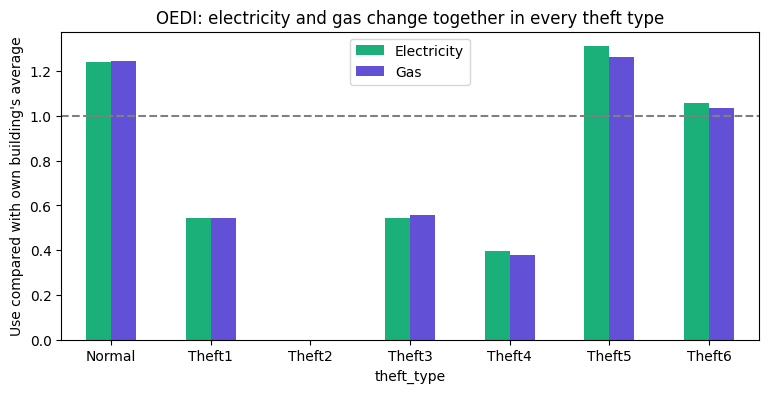

,Electricity,Gas
theft_type,,
Normal,1.24,1.25
Theft1,0.54,0.54
Theft2,0.00,0.00
Theft3,0.55,0.56
Theft4,0.40,0.38
Theft5,1.31,1.26
Theft6,1.06,1.04


In [48]:
gas_average = oedi.groupby("recording_id")["gas_facility_kw"].transform("mean")
oedi["gas_vs_average"] = oedi["gas_facility_kw"] / gas_average

gas_compare = oedi.groupby("theft_type")[["elec_vs_average", "gas_vs_average"]].mean()
gas_compare.columns = ["Electricity", "Gas"]   # these names appear in the legend

gas_compare.plot.bar(figsize=(9, 4), color=["#1baf7a", "#6250d6"], rot=0)
plt.axhline(1.0, color="gray", linestyle="--")
plt.ylabel("Use compared with own building's average")
plt.title("OEDI: electricity and gas change together in every theft type")
plt.savefig(f"{FIG_DIR}/fig07_oedi_gas.png", dpi=150)
plt.show()

gas_compare.round(2)

**Insight:**

- **Yes, gas changes too, by the same amount as electricity** in every theft type
  (for example Theft1: electricity 0.54, gas 0.54; Theft2 has no bars because both
  are 0). The theft generator changed the whole row, not only electricity.
- So gas **cannot** serve as an honest reference in this dataset.
- **Limitation:** in real life, a person stealing electricity would not lower their gas
  meter too. This shows that the OEDI theft is simulated and may be easier or different
  from real theft. We should say this in the report, and results on OEDI may not carry
  over to real customers.

## 7. Summary of findings

| # | Finding | What it means for the project |
|---|---|---|
| 1 | SGCC is very imbalanced (8.5% theft); OEDI is 40.8% | Do not trust accuracy alone; report precision and recall; use class weights |
| 2 | Theft customers had about twice as many missing days | `missing_share` is a useful feature, but not proof |
| 3 | Usage has normal rhythms (seasons, day and night) | A drop alone is not theft; compare each customer with their own usual use |
| 4 | SGCC theft customers use more and more irregularly; zero days are more common among normal customers | Build variability and sudden-drop features; do not rely on zero days |
| 5 | OEDI Theft5 and Theft6 keep a normal amount of use | Need pattern features: hour of day and 24-hour window statistics per recording |
| 6 | In OEDI, gas changes together with electricity | Gas is not an honest reference; the simulated theft is a limitation |

These findings guide the feature module (PR 4).